# 06 — Full-refit uncertainty and independent-cycle evaluation

This results notebook reads the completed extension outputs. The executable analysis lives
in `research_extension.py`; the analysis protocol predates extension results. Original notebooks
01–04 remain separate. Run from the root or notebooks directory after installing requirements.txt.
Notebook 05 can rerun all analyses and 100 full-refit replicates by setting RUN_ANALYSIS=True.

See [full interpretation](../docs/findings/research_extension_results.md),
[harmonization](../docs/methods/cycle_harmonization.md), and
[literature matrix](../literature/extension_evidence_matrix.md).
This is exploratory research; no safe clinical deferral policy is established.

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CODEX.md').is_file())
sys.path.insert(0, str(ROOT / 'scripts/analysis'))
OUT = ROOT / 'results/research_extension'


| Predictors | Current-cycle OOF AUROC | Independent-cycle AUROC | Current Brier | Independent Brier |
| --- | --- | --- | --- | --- |
| demographics | 0.693 | 0.664 | 0.01932 | 0.02004 |
| demographics_bmi | 0.799 | 0.762 | 0.01926 | 0.01987 |
| demographics_bmi_cbc | 0.823 | 0.799 | 0.01902 | 0.02059 |

The 100-replicate CBC gain interval includes zero. Independent-cycle AUROC improves while Brier/log-loss worsen. Bootstrap intervals fix splits; independent jackknife intervals fix developed models.

In [2]:
print('\nfull_refit_bootstrap_intervals.csv')
print(pd.read_csv(OUT / 'full_refit_bootstrap_intervals.csv').to_string(index=False))
print('\npaired_conditional_design_gains.csv')
print(pd.read_csv(OUT / 'paired_conditional_design_gains.csv').to_string(index=False))
print('\ncycle_counts.csv')
print(pd.read_csv(OUT / 'cycle_counts.csv').to_string(index=False))


full_refit_bootstrap_intervals.csv
               model            metric  successful_replicates     lower    upper
        demographics             AUROC                    100  0.521644 0.764629
        demographics                AP                    100  0.024517 0.064834
        demographics             Brier                    100  0.015051 0.022415
        demographics       sensitivity                    100  0.844076 1.000000
        demographics deferred_fraction                    100  0.045160 0.340620
    demographics_bmi             AUROC                    100  0.669865 0.851675
    demographics_bmi                AP                    100  0.031158 0.090703
    demographics_bmi             Brier                    100  0.014960 0.022256
    demographics_bmi       sensitivity                    100  0.847414 0.992993
    demographics_bmi deferred_fraction                    100  0.198575 0.486982
demographics_bmi_cbc             AUROC                    100  0.691592 0

Generated figure: `independent_cycle_calibration.png`. Interpret alongside the report; subgroup changes and assumed utility trade-offs do not establish causation or safety.

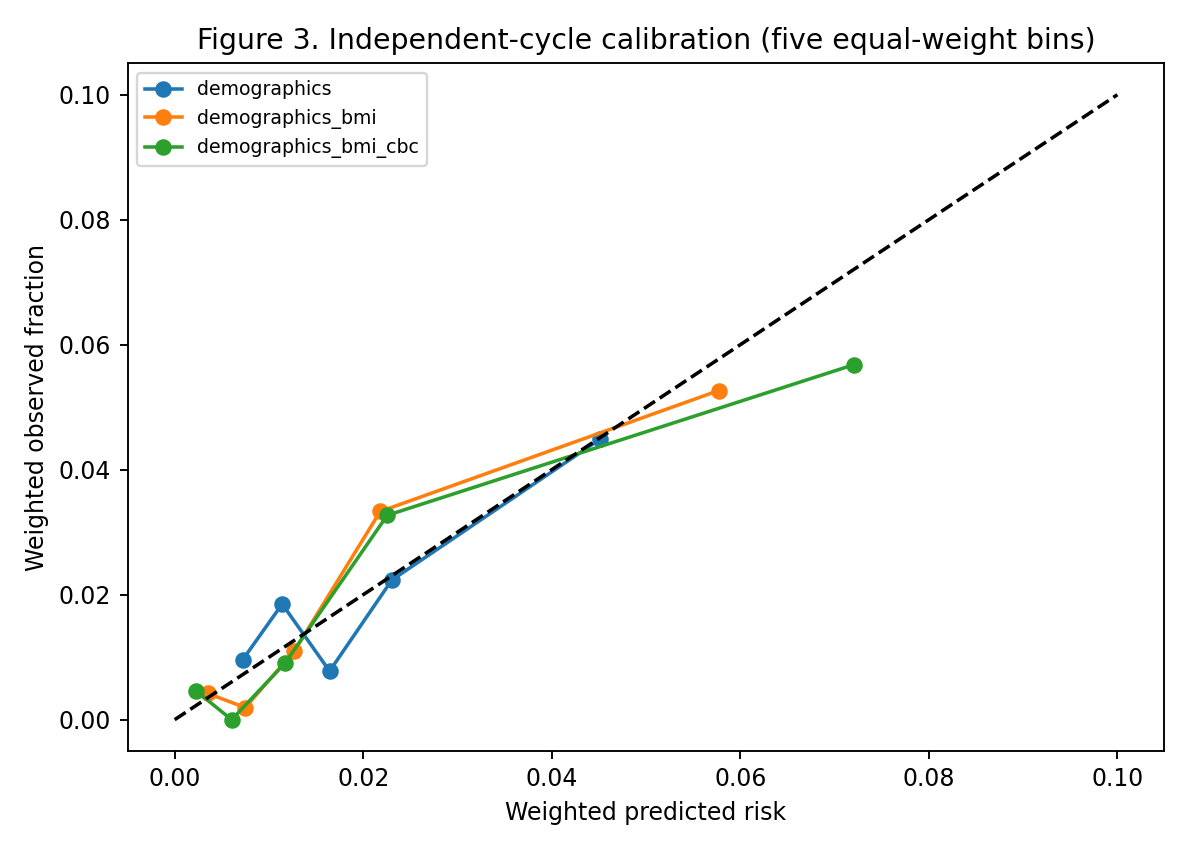

In [3]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'independent_cycle_calibration.png')))

Generated figure: `decision_curves.png`. Interpret alongside the report; subgroup changes and assumed utility trade-offs do not establish causation or safety.

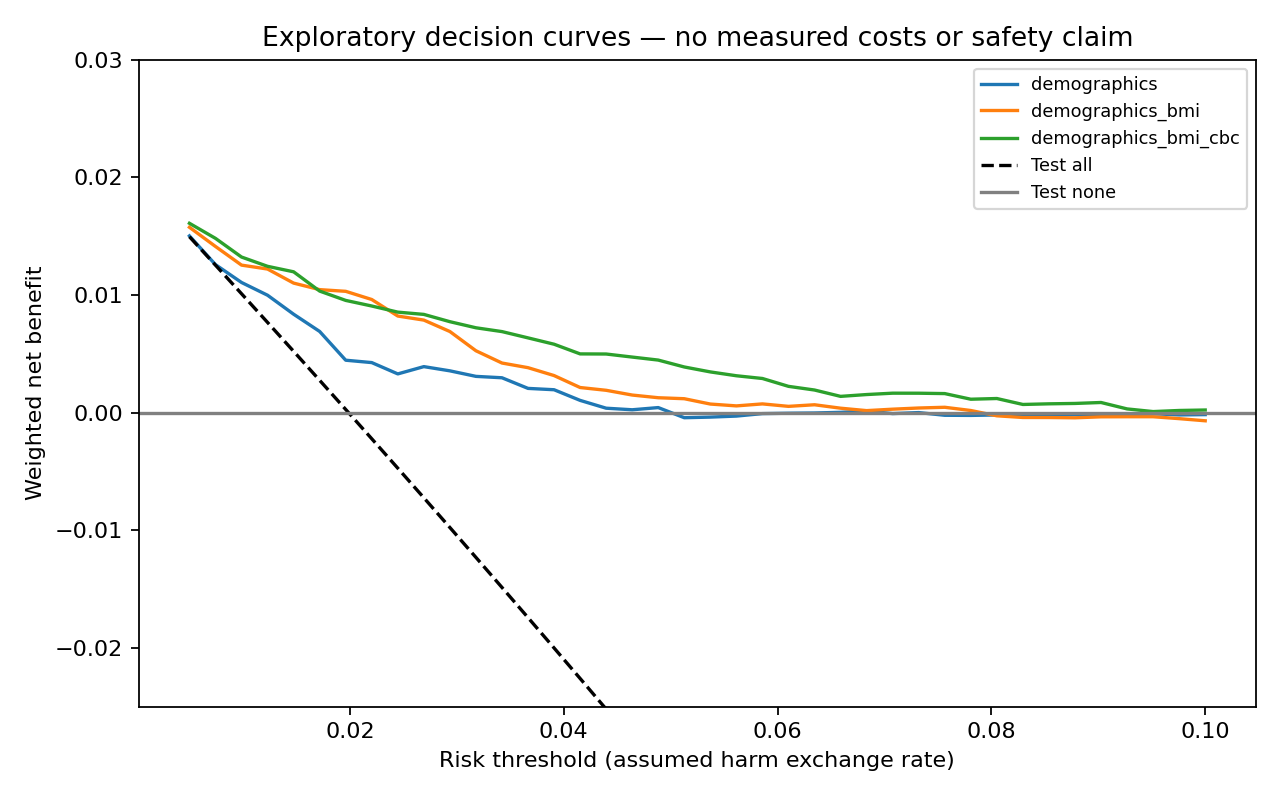

In [4]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'decision_curves.png')))